# Activity risk from inhaled PM2.5

Takes a planned run, or any other outdoor activity, and returns how many micrograms of PM2.5 it puts in the lungs, what that does to the day's total,
and a Low, Medium or High risk level with reasons and safer start times.

```
calculate-ve.ipynb         run plan + profile + history  ->  VE (L/min) with an 80% band
calculate-ve-others.ipynb  any other activity + profile  ->  MET -> VO2 -> VE with an 80% band
air-weather-api.ipynb      place                         ->  hourly PM2.5 forecast
this notebook              VE x PM2.5 x minutes      ->  µg inhaled -> day-equivalent PM2.5 -> risk level
```

**Why not the textbook method.** Health risk assessments such as
[Thabethe et al. 2025](https://doi.org/10.3389/fpubh.2025.1515009) follow the US EPA recipe: hazard quotient
HQ = C_adj / RfC, with C_adj = PM2.5 × (hours exposed / 24) × (days / 365). Three things stop it working for a run:

* C_adj weights hours, not air. An hour of running counts the same as an hour on the sofa, though the runner inhales
  five to six times more.
* The RfC values it uses are annual limits (WHO 5, US EPA 9, South Africa 20 µg/m³). One run against a yearly
  average says nothing.
* Its cancer risk uses 0.008 per µg/m³, which looks like Pope et al. 2002's 8% rise in lung cancer deaths per
  10 µg/m³. That's a relative increase used as an absolute lifetime risk, which is how the paper ends up with 1 in 10
  older adults getting cancer at 17 µg/m³. This notebook has no cancer term.

What carries over is the hazard quotient idea: dose over a safe dose, with values above 1 flagged. Section 4 swaps the
share of time for the share of air.

## 1. Setup

Runs the upstream notebooks and keeps their functions: `estimate_ve` from `calculate-ve.ipynb` for runs,
`estimate_ve_activity` and `resolve_activity` from `calculate-ve-others.ipynb` for everything else, and
`conditions_timeline` from `air-weather-api.ipynb`. Their outputs are hidden. Together they take about 30 s and
need internet for Open-Meteo.

In [1]:
%%capture
%run calculate-ve-others.ipynb
%run calculate-ve.ipynb
%run air-weather-api.ipynb

In [2]:
import re
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# chart tokens (light mode), same as explore.ipynb; status colors are reserved for risk levels
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"Low": "#0ca30c", "Medium": "#fab219", "High": "#d03b3b"}

## 2. Inputs

In [3]:
PLACE = {"name": "East Coast Park", "lat": 1.3010, "lon": 103.9120}
START = "20:00"          # local time, today or tomorrow if already past; a full date also works: "2026-10-18 07:00"
PLAN = {"pace": "6:00", "distance_km": 10.0}   # a run; any other activity: {"activity": "badminton", "intensity": "moderate", "minutes": 90}
PERSON = {"age": 30, "sex": "male", "height_cm": 175, "weight_kg": 70}
HISTORY = {"best_effort": {"distance_km": 5.0, "time": "25:00"},
           "runs": [{"distance_km": 8.0, "time": "52:00", "avg_hr": 148},
                    {"distance_km": 5.0, "time": "30:00", "avg_hr": 155},
                    {"distance_km": 10.0, "time": "58:00", "avg_hr": 160}]}
GROUP = "general"        # "general", or "vulnerable": older adults, children, pregnancy, heart or lung disease
INDOOR_RATIO = 1.0       # PM2.5 for the rest of the day as a share of outdoor; 1.0 assumes outdoor air all day

## 3. Reference values

**Daily air volume by age.** US EPA Exposure Factors Handbook (2011), Table 6-1, long-term mean, males and females
combined.

**WHO 2021 24-hour PM2.5 levels.** Guideline 15 µg/m³, with interim targets IT-4 25, IT-3 37.5, IT-2 50 and IT-1 75.

**NEA 1-hour PM2.5 bands.** Band I Normal ≤ 55, Band II Elevated 56 to 150, Band III High 151 to 250, Band IV Very
High ≥ 251. NEA says the 1-hour reading is for immediate outdoor plans and the 24-hour PSI for planning ahead.

**Risk levels.** These are my proposal, not a published standard. The day-equivalent PM2.5 from §4 is scored against
the WHO tiers:

| level | general | vulnerable |
|---|---|---|
| Low | below 37.5 (IT-3) | below 25 (IT-4) |
| Medium | 37.5 to 75 | 25 to 50 |
| High | 75 and up (above IT-1, the loosest WHO target) | 50 and up |


High starts at haze levels on purpose. [Tainio et al. 2016](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4893018/)
found the health benefit of cycling and walking outweighs PM2.5 harm at 22 µg/m³ even at extreme amounts of
activity. At 100 µg/m³, harm overtook benefit after 1.5 hours of cycling a day. Running moves more air than
commuter cycling, so its break-even comes sooner, but a typical day is still a day to run. Vulnerable groups also get
the upper end of the VE band (p90) rather than the central estimate.

In [4]:
# (age upper bound, m3/day); EPA EFH Table 6-1
V_DAY_TABLE = [(1, 5.4), (2, 8.0), (3, 8.9), (6, 10.1), (11, 12.0), (16, 15.2), (21, 16.3), (31, 15.7), (41, 16.0),
               (51, 16.0), (61, 15.7), (71, 14.2), (81, 12.9), (np.inf, 12.2)]
WHO_24H = [(15, "WHO guideline"), (25, "WHO IT-4"), (37.5, "WHO IT-3"), (50, "WHO IT-2"), (75, "WHO IT-1")]
NEA_BANDS = [(55, "Band I Normal"), (150, "Band II Elevated"), (250, "Band III High"), (np.inf, "Band IV Very High")]
LEVELS = {"general": [(37.5, "Low"), (75, "Medium"), (np.inf, "High")],
          "vulnerable": [(25, "Low"), (50, "Medium"), (np.inf, "High")]}


def v_day(age):
    return next(v for top, v in V_DAY_TABLE if age < top)


def nea_band(pm):
    return next(name for top, name in NEA_BANDS if pm <= top)


def who_tier(c):
    over = [name for top, name in WHO_24H if c > top]
    return f"above {over[-1]} ({dict((n, t) for t, n in WHO_24H)[over[-1]]:g})" if over else "within WHO guideline (15)"


def risk_level(c_eq, group):
    level = next(name for top, name in LEVELS[group] if c_eq < top)
    return level, [f"day-equivalent PM2.5 {c_eq:.0f} µg/m³, {who_tier(c_eq)}"]

## 4. Dose and day-equivalent PM2.5

PM2.5 comes in hourly and is interpolated to each minute. With VE in L/min and PM2.5 in µg/m³:

* run dose (µg) = Σ over the run's minutes of PM2.5 × VE / 1000
* rest-of-day dose (µg) = INDOOR_RATIO × Σ over the day's other minutes of PM2.5 × V_day / 1440
* day-equivalent PM2.5 C_eq = (run dose + rest-of-day dose) / V_day
* hazard quotient HQ = C_eq / 15

C_eq is the 24-hour concentration at which someone breathing an ordinary day for their age would take in the same
micrograms. So WHO's 24-hour numbers apply to it directly, adjusted for how hard this person breathes. "Day" means the
calendar day the run starts on.

In [5]:
def _at(pm, times):
    # PM2.5 at each time, linear between forecast hours
    return np.interp(times.as_unit("s").asi8, pm.index.as_unit("s").asi8, pm.to_numpy())


def assess(pm, start, minutes, ve_lmin, age, group="general", indoor_ratio=1.0):
    run_t = pd.date_range(start, periods=int(round(minutes)), freq="min")
    day_t = pd.date_range(start.normalize(), periods=1440, freq="min")
    run_ug = np.sum(_at(pm, run_t) * ve_lmin / 1000)
    vd = v_day(age)
    others = ~day_t.isin(run_t)
    rest_ug = indoor_ratio * np.sum(_at(pm, day_t[others]) * vd / 1440)
    c_eq = (run_ug + rest_ug) / vd
    max_hour = pm.loc[start.floor("h"): run_t[-1].ceil("h")].max()   # every forecast hour the interpolation touches
    level, reasons = risk_level(c_eq, group)
    notes = []
    if day_t[0] < pm.index.min() or day_t[-1] > pm.index.max() + pd.Timedelta(hours=1):
        notes.append("part of the day is outside the forecast; its edge hour fills the gap")
    return {"start": start, "minutes": minutes, "ve_lmin": ve_lmin, "run_pm_mean": run_ug * 1000 / ve_lmin / len(run_t),
            "run_pm_max_hour": max_hour, "day_pm_mean": _at(pm, day_t).mean(), "run_ug": run_ug, "rest_ug": rest_ug,
            "v_day_m3": vd, "c_eq": c_eq, "hq": c_eq / 15, "run_share_of_day": run_ug / (run_ug + rest_ug),
            "level": level, "reasons": reasons, "notes": notes}

## 5. Checks

A flat PM2.5 series makes the arithmetic easy to verify:

* A "run" breathed at the day-average rate must give C_eq equal to the PM2.5 level.
* Doubling PM2.5 must double the dose and C_eq.
* The thresholds must land where §3 says.

Then the worked example: the `calculate-ve.ipynb` runner, 10 km at 6:00/km on the no-history model, at flat PM2.5
levels.

In [6]:
SGT = ZoneInfo("Asia/Singapore")
flat = lambda level: pd.Series(level, index=pd.date_range("2026-01-01", periods=72, freq="h", tz=SGT), dtype=float)
t0 = pd.Timestamp("2026-01-02 20:00", tz=SGT)

avg_ve = v_day(30) / 1440 * 1000
assert np.isclose(assess(flat(40), t0, 60, avg_ve, 30)["c_eq"], 40)
a, b = assess(flat(20), t0, 60, 65, 30), assess(flat(40), t0, 60, 65, 30)
assert np.isclose(b["run_ug"], 2 * a["run_ug"]) and np.isclose(b["c_eq"], 2 * a["c_eq"])
assert np.isclose(assess(flat(40), t0, 60, 65, 30, indoor_ratio=0.5)["rest_ug"], 0.5 * b["rest_ug"])

assert risk_level(37.4, "general")[0] == "Low" and risk_level(37.5, "general")[0] == "Medium"
assert risk_level(74.9, "general")[0] == "Medium" and risk_level(75, "general")[0] == "High"
assert risk_level(24.9, "vulnerable")[0] == "Low" and risk_level(50, "vulnerable")[0] == "High"
assert v_day(30) == 15.7 and v_day(31) == 16.0 and v_day(70) == 14.2 and v_day(85) == 12.2
print("checks pass")

ex = estimate_ve({"pace": "6:00", "distance_km": 10.0}, {"age": 30, "sex": "male", "height_cm": 175, "weight_kg": 70})
rows = []
for level in [15, 20, 37.5, 55, 100, 150]:
    r = assess(flat(level), t0, ex["minutes"], ex["ve_lmin"], 30)
    rows.append({"PM2.5 all day": level, "run µg": r["run_ug"], "share of WHO day budget %": 100 * r["run_ug"] / (15 * r["v_day_m3"]),
                 "day-equivalent µg/m³": r["c_eq"], "added by run": r["c_eq"] - level, "HQ": r["hq"], "level": r["level"]})
print(f"VE {ex['ve_lmin']:.1f} L/min for {ex['minutes']:.0f} min; WHO day budget = 15 × {v_day(30)} m³ = {15 * v_day(30):.0f} µg")
display(pd.DataFrame(rows).set_index("PM2.5 all day").round(1))

checks pass
VE 64.6 L/min for 60 min; WHO day budget = 15 × 15.7 m³ = 236 µg


,run µg,share of WHO day budget %,day-equivalent µg/m³,added by run,HQ,level
PM2.5 all day,,,,,,
15.0,58.2,24.7,18.1,3.1,1.2,Low
20.0,77.6,32.9,24.1,4.1,1.6,Low
37.5,145.4,61.8,45.2,7.7,3.0,Medium
55.0,213.3,90.6,66.3,11.3,4.4,Medium
100.0,387.8,164.7,120.5,20.5,8.0,High
150.0,581.7,247.0,180.8,30.8,12.1,High


At any flat PM2.5 level the run adds about 20% to the day's dose. The run scales the risk, and the PM2.5 level sets
it. That's why the alternatives in §7 lean on timing: the same run in a cleaner hour does more than slowing down.

## 6. The planned run

In [7]:
tl = conditions_timeline(PLACE["lat"], PLACE["lon"])
tz = ZoneInfo(tl.attrs["timezone"])
pm = tl.pm25_ugm3.dropna()
now = pd.Timestamp.now(tz=tz)


def resolve_start(s):
    if re.fullmatch(r"\d{1,2}:\d{2}", s):
        h, mi = map(int, s.split(":"))
        t = now.normalize() + pd.Timedelta(hours=h, minutes=mi)
        return t if t >= now else t + pd.Timedelta(days=1)
    t = pd.Timestamp(s)
    return t.tz_localize(tz) if t.tzinfo is None else t.tz_convert(tz)


def is_run(plan):
    return "pace" in plan


def describe(plan):
    if is_run(plan):
        return f"{plan['distance_km']:g} km at {plan['pace']} min/km"
    a = resolve_activity(plan["activity"], plan.get("intensity", "moderate"))
    what = a["family_name"] if a and a["family"] else a["name"] if a else plan["activity"]
    return f"{what}, {plan.get('intensity', 'moderate')}, {plan['minutes']:g} min"


def estimate(plan):
    # runs use pace and history (calculate-ve.ipynb); anything else goes MET -> VO2 -> VE (calculate-ve-others.ipynb)
    return estimate_ve(plan, PERSON, HISTORY) if is_run(plan) else estimate_ve_activity(plan, PERSON)


def run_risk(plan, start, group=GROUP):
    v = estimate(plan)
    ve = v["ve_p90"] if group == "vulnerable" else v["ve_lmin"]
    end = start + pd.Timedelta(minutes=v["minutes"])
    if end > pm.index.max() + pd.Timedelta(hours=1):
        raise ValueError(f"session ends {end:%a %d %b %H:%M}, past the PM2.5 forecast ({pm.index.max():%a %d %b %H:%M})")
    r = assess(pm, start, v["minutes"], ve, PERSON["age"], group, INDOOR_RATIO)
    r["ve"] = v
    r["band"] = {k: assess(pm, start, v["minutes"], v[k], PERSON["age"], group, INDOOR_RATIO) for k in ["ve_p10", "ve_p90"]}
    return r


start = resolve_start(START)
FOUND = is_run(PLAN) or resolve_activity(PLAN["activity"], PLAN.get("intensity", "moderate")) is not None
if not FOUND:
    print(f"Activity not found: {PLAN['activity']!r}. Nothing in hazewise.db matches it, so there is no dose or risk "
          f"level. The forecast in §7 still applies.")
else:
    plan_r = run_risk(PLAN, start)
    v = plan_r["ve"]
    lo, hi = plan_r["band"]["ve_p10"], plan_r["band"]["ve_p90"]
    print(f"{PLACE['name']}, {start:%a %d %b %H:%M} to {start + pd.Timedelta(minutes=v['minutes']):%H:%M}: "
          f"{describe(PLAN)}, {GROUP} thresholds")
    print(f"PM2.5 during the session {plan_r['run_pm_mean']:.0f} µg/m³ (worst hour {plan_r['run_pm_max_hour']:.0f}, "
          f"{nea_band(plan_r['run_pm_max_hour'])}); day mean {plan_r['day_pm_mean']:.0f}")
    print(f"VE {plan_r['ve_lmin']:.1f} L/min (model {v['variant']}, 80% band {v['ve_p10']:.1f}-{v['ve_p90']:.1f}"
          + (", vulnerable thresholds use the top of the band)" if GROUP == "vulnerable" else ")"))
    print(f"\nInhaled during the session {plan_r['run_ug']:.0f} µg  (80% band {lo['run_ug']:.0f}-{hi['run_ug']:.0f}), "
          f"{100 * plan_r['run_share_of_day']:.0f}% of the day's dose")
    print(f"Day-equivalent PM2.5       {plan_r['c_eq']:.1f} µg/m³ (80% band {lo['c_eq']:.1f}-{hi['c_eq']:.1f}), HQ {plan_r['hq']:.1f}")
    skip_c = INDOOR_RATIO * plan_r["day_pm_mean"]
    skip_level = risk_level(skip_c, GROUP)[0]
    print(f"Without the session        {skip_c:.1f} µg/m³ ({skip_level})")
    print(f"\nRisk: {plan_r['level'].upper()}")
    for line in plan_r["reasons"] + plan_r["notes"] + (v["notes"] if not is_run(PLAN) else []) + v["warnings"]:
        print(f"  · {line}")

East Coast Park, Sat 17 Oct 20:00 to 21:00: 10 km at 6:00 min/km, general thresholds
PM2.5 during the session 41 µg/m³ (worst hour 41, Band I Normal); day mean 69
VE 72.6 L/min (model B, 80% band 60.3-84.4)

Inhaled during the session 177 µg  (80% band 147-206), 14% of the day's dose
Day-equivalent PM2.5       78.7 µg/m³ (80% band 76.8-80.6), HQ 5.2
Without the session        69.2 µg/m³ (Medium)

Risk: HIGH
  · day-equivalent PM2.5 79 µg/m³, above WHO IT-1 (75)


## 7. Safer alternatives

The same session at every whole-hour start from 05:00 to 21:00 within the forecast. The table compares the plan
with skipping it, a shorter and an easier version at the planned time, and the lowest-dose start on each forecast
day. For a run, shorter is half the distance and easier is 1 min/km slower. For other activities, shorter is half
the time and easier is one intensity step down, when the activity has one.

In [8]:
if FOUND:
    first = max(now.ceil("h"), pm.index.min())
    last = pm.index.max() + pd.Timedelta(hours=1) - pd.Timedelta(minutes=v["minutes"])
    starts = [t for t in pd.date_range(first, last, freq="h") if 5 <= t.hour <= 21]
    by_start = pd.DataFrame([{k: r[k] for k in ["start", "run_ug", "c_eq", "level"]}
                             for r in (run_risk(PLAN, t) for t in starts)]).set_index("start")

    if is_run(PLAN):
        slower = {**PLAN, "pace": f"{int(to_minutes(PLAN['pace']) + 1)}:{round(to_minutes(PLAN['pace']) % 1 * 60):02d}"}
        options = {f"half distance ({PLAN['distance_km'] / 2:g} km)": ({**PLAN, "distance_km": PLAN["distance_km"] / 2}, start),
                   f"1 min/km slower ({slower['pace']})": (slower, start)}
    else:
        options = {f"half the time ({PLAN['minutes'] / 2:g} min)": ({**PLAN, "minutes": PLAN["minutes"] / 2}, start)}
        steps = INTENSITIES[:INTENSITIES.index(PLAN.get("intensity", "moderate"))]
        if steps and resolve_activity(PLAN["activity"])["family"]:
            options[f"{steps[-1]} intensity"] = ({**PLAN, "intensity": steps[-1]}, start)
    options |= {f"best start {t:%a}": (PLAN, t) for t in by_start.groupby(by_start.index.date).run_ug.idxmin()}

    cols = ["start", "minutes", "ve_lmin", "run_pm_mean", "run_ug", "c_eq", "level"]
    rows = {"as planned": {k: plan_r[k] for k in cols},
            "skip it": {"start": start, "minutes": 0, "ve_lmin": np.nan, "run_pm_mean": np.nan, "run_ug": 0.0,
                        "c_eq": skip_c, "level": skip_level}}
    rows |= {name: {k: r[k] for k in cols} for name, r in ((n, run_risk(p, t)) for n, (p, t) in options.items())}
    table = pd.DataFrame(rows).T.astype({c: float for c in cols if c not in ("start", "level")})
    table["start"] = table.start.map(lambda t: f"{t:%a %d %b %H:%M}")
    table.insert(5, "vs planned µg", table.run_ug - plan_r["run_ug"])
    display(table.round(1))

,start,minutes,ve_lmin,run_pm_mean,run_ug,vs planned µg,c_eq,level
as planned,Sat 17 Oct 20:00,60.0,72.6,40.7,177.0,0.0,78.7,High
skip it,Sat 17 Oct 20:00,0.0,NaN,NaN,0.0,-177.0,69.2,Medium
half distance (5 km),Sat 17 Oct 20:00,30.0,72.6,41.0,89.3,-87.7,74.0,Medium
1 min/km slower (7:00),Sat 17 Oct 20:00,70.0,60.8,40.6,172.6,-4.4,78.2,High
best start Sat,Sat 17 Oct 21:00,60.0,72.6,39.9,173.5,-3.5,78.6,High
best start Sun,Sun 18 Oct 05:00,60.0,72.6,25.8,112.5,-64.5,41.6,Medium
best start Mon,Mon 19 Oct 10:00,60.0,72.6,38.2,166.5,-10.5,51.4,Medium
best start Tue,Tue 20 Oct 21:00,60.0,72.6,39.9,173.7,-3.3,53.3,Medium
best start Wed,Wed 21 Oct 21:00,60.0,72.6,23.6,102.8,-74.3,34.0,Low
best start Thu,Thu 22 Oct 05:00,60.0,72.6,16.8,73.1,-103.9,22.5,Low


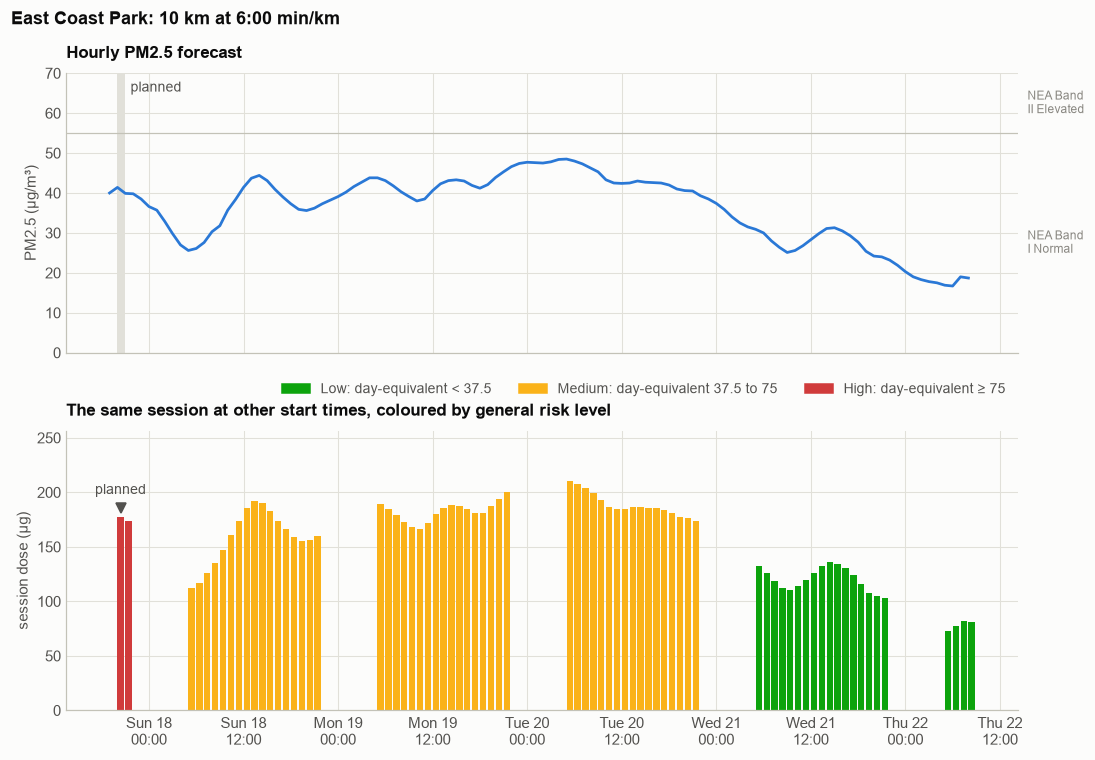

In [9]:
win = pm.loc[now.floor("h"):]
fig, axes = plt.subplots(2 if FOUND else 1, 1, figsize=(10, 7 if FOUND else 3.8), sharex=True, squeeze=False)
axes = axes[:, 0]

ax = axes[0]
ax.plot(win.index, win.values, color=C[0])
ax.set(ylabel="PM2.5 (µg/m³)", title="Hourly PM2.5 forecast", ylim=(0, max(win.max() * 1.15, 70)))
lo_ = 0
for top, name in NEA_BANDS:
    hi_ = min(top, ax.get_ylim()[1])
    if lo_ < hi_:
        if top < ax.get_ylim()[1]:
            ax.axhline(top, color=AXIS, lw=0.8)
        ax.text(1.01, (lo_ + hi_) / 2, f"NEA {name.replace(' ', chr(10), 1)}", transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=8, color=MUTED, clip_on=False)
    lo_ = top

if FOUND:
    end = start + pd.Timedelta(minutes=v["minutes"])
    ax.axvspan(start, end, color=GRID, lw=0, zorder=0)
    ax.text(end + pd.Timedelta(minutes=40), ax.get_ylim()[1] * 0.97, "planned", ha="left", va="top", fontsize=9, color=INK2)

    ax = axes[1]
    ax.bar(by_start.index, by_start.run_ug, width=1 / 24 * 0.8, align="edge", color=by_start.level.map(STATUS), lw=0)
    ax.set(ylabel="session dose (µg)", title=f"The same session at other start times, coloured by {GROUP} risk level",
           ylim=(0, by_start.run_ug.max() * 1.22))
    th = LEVELS[GROUP]
    ax.legend(handles=[Patch(color=STATUS[n], label=f"{n}: day-equivalent {lab}")
                       for n, lab in zip(["Low", "Medium", "High"], [f"< {th[0][0]:g}", f"{th[0][0]:g} to {th[1][0]:g}", f"≥ {th[1][0]:g}"])],
              loc="lower right", bbox_to_anchor=(1, 1.08), ncols=3)
    if start in by_start.index:
        # marker above the tallest nearby bar, so the label never sits on a neighbour
        x = start + pd.Timedelta(minutes=24)
        y = by_start.run_ug.loc[start - pd.Timedelta(hours=3): start + pd.Timedelta(hours=3)].max() * 1.05
        ax.plot(x, y, marker="v", ms=7, color=INK2)
        ax.annotate("planned", (x, y), xytext=(0, 7), textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK2)

axes[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d\n%H:%M", tz=tz))
title = describe(PLAN) if FOUND else f"{PLAN['activity']} (activity not found)"
fig.suptitle(f"{PLACE['name']}: {title}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

How to read the options, whatever the forecast:

* **Timing moves the most.** A cleaner hour lowers the run dose. On another day it changes the day's score as well.
* **Slowing down barely helps.** A slower pace lowers VE but stretches the run, and air per km is nearly flat across
  running paces (`explore.ipynb` §13).
* **Shortening halves the run dose,** but the day's score moves less, because most of the day's air is breathed
  outside the run.
* **Skipping it shows the floor.** If that row is already High, the day itself is the problem, and the honest
  advice is to train indoors or on another day.

## 8. Other activities

The same place, start and person with activities that have no pace. `run_risk` sends them through
`calculate-ve-others.ipynb`: the activity's Compendium MET from `hazewise.db`, VO2 = MET × 3.5 × weight, then the
VO2 → VE model. An activity the database doesn't know comes back as not found, and §7's forecast is all there is.

In [10]:
others = [{"activity": "badminton", "intensity": "moderate", "minutes": 90},
          {"activity": "muay thai", "intensity": "vigorous", "minutes": 60},
          {"activity": "cycling", "intensity": "moderate", "minutes": 60},
          {"activity": "park gym", "intensity": "moderate", "minutes": 45},
          {"activity": "tai chi", "intensity": "light", "minutes": 60},
          {"activity": "underwater basket weaving", "intensity": "moderate", "minutes": 60}]
rows = {}
for p in others:
    if resolve_activity(p["activity"], p["intensity"]) is None:
        rows[p["activity"]] = {"activity": "", "level": "activity not found"}
        continue
    r = run_risk(p, start)
    rows[p["activity"]] = {"activity": describe(p), "MET": r["ve"]["met"], "VE L/min": r["ve_lmin"],
                           "band": f"{r['ve']['ve_p10']:.0f}-{r['ve']['ve_p90']:.0f}", "µg": r["run_ug"], "c_eq": r["c_eq"],
                           "level": r["level"]}
if FOUND:
    rows = {"planned: " + describe(PLAN): {"activity": describe(PLAN), "MET": np.nan, "VE L/min": plan_r["ve_lmin"],
            "band": f"{v['ve_p10']:.0f}-{v['ve_p90']:.0f}", "µg": plan_r["run_ug"], "c_eq": plan_r["c_eq"],
            "level": plan_r["level"]}} | rows
display(pd.DataFrame(rows).T.drop(columns="activity").round(1))

,MET,VE L/min,band,µg,c_eq,level
planned: 10 km at 6:00 min/km,NaN,72.56,60-84,177.02,78.75,High
badminton,7.0,41.5,30-56,150.88,76.25,High
muay thai,14.3,108.27,78-146,264.15,84.3,High
cycling,7.0,41.5,30-56,101.24,73.92,Medium
park gym,5.0,29.2,21-39,53.67,71.31,Medium
tai chi,1.5,10.06,7-14,24.54,69.04,Medium
underwater basket weaving,NaN,NaN,NaN,NaN,NaN,activity not found


Lighter activities move less air, so they add less to the day, but the day's own PM2.5 still sets the floor: if
skipping already scores Medium or High, no activity choice brings it to Low.

## 9. Limits

* **Dose is a modelling choice.** WHO's 24-hour limits come from population studies of air concentration, not of
  inhaled micrograms. Scaling them by breathing assumes harm follows dose. That's the natural reading, but no study
  in this notebook tests it.
* **The levels are my proposal.** They're built from WHO tiers and NEA bands, but no agency publishes them for
  exercise.
* **The rest of the day is assumed outdoors** (INDOOR_RATIO = 1). Indoor air is usually cleaner during haze, so C_eq
  leans high. That's the cautious direction, but it's still a guess until there's indoor data.
* **The forecast is coarse.** CAMS runs on a grid of about 45 km, so every point in Singapore shares one or two cells,
  and local plumes don't show.
* **Heat is separate.** It raises VE and strain, and neither is in this score yet.
* **VE has its own limits** (`calculate-ve.ipynb` §10): ages 11 to 63, speeds from 4.9 km/h, no data on long runs.
  For other activities (`calculate-ve-others.ipynb` §10) the MET is a session average from the Compendium, and
  stop-start sports likely breathe more than it implies. Warnings print with the result.